## Assignment no 18

## SONAR: Mines vs. Rocks — Artificial Neural Network Classification

1. Install required libraries

2. Import libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and splitting
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Neural network
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


3. Load the dataset

In [2]:
# Dataset path
file_path = "sonardataset.csv"

# Load dataset without assuming column headers
df = pd.read_csv(file_path, header=None)

# Display first five rows
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_52,x_53,x_54,x_55,x_56,x_57,x_58,x_59,x_60,Y
1,0.02,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.018,0.0084,0.009,0.0032,R
2,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.014,0.0049,0.0052,0.0044,R
3,0.0262,0.0582,0.1099,0.1083,0.0974,0.228,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.018,0.0244,0.0316,0.0164,0.0095,0.0078,R
4,0.01,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.015,0.0085,0.0073,0.005,0.0044,0.004,0.0117,R


Dataset Shape: (209, 61)


In [3]:
# Check whether dataset contains 60 features and 1 target
if df.shape[1] != 61:
    raise ValueError(
        f"Expected 61 columns (60 features + 1 target), "
        f"but found {df.shape[1]} columns. "
        "Check the dataset format."
    )

# Assign feature names
df.columns = [f"V{i}" for i in range(1, 61)] + ["Target"]

# Display first five rows
display(df.head())

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V52,V53,V54,V55,V56,V57,V58,V59,V60,Target
0,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_52,x_53,x_54,x_55,x_56,x_57,x_58,x_59,x_60,Y
1,0.02,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.018,0.0084,0.009,0.0032,R
2,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.014,0.0049,0.0052,0.0044,R
3,0.0262,0.0582,0.1099,0.1083,0.0974,0.228,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.018,0.0244,0.0316,0.0164,0.0095,0.0078,R
4,0.01,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.015,0.0085,0.0073,0.005,0.0044,0.004,0.0117,R


4. Data exploration and preprocessing

4.1 Dataset information

In [4]:
# Number of rows and columns
print("Number of samples:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of input features:", df.shape[1] - 1)

# Dataset information
df.info()

# Statistical summary
display(df.describe())

Number of samples: 209
Number of columns: 61
Number of input features: 60
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   V1      209 non-null    object
 1   V2      209 non-null    object
 2   V3      209 non-null    object
 3   V4      209 non-null    object
 4   V5      209 non-null    object
 5   V6      209 non-null    object
 6   V7      209 non-null    object
 7   V8      209 non-null    object
 8   V9      209 non-null    object
 9   V10     209 non-null    object
 10  V11     209 non-null    object
 11  V12     209 non-null    object
 12  V13     209 non-null    object
 13  V14     209 non-null    object
 14  V15     209 non-null    object
 15  V16     209 non-null    object
 16  V17     209 non-null    object
 17  V18     209 non-null    object
 18  V19     209 non-null    object
 19  V20     209 non-null    object
 20  V21     209 non-null    

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V52,V53,V54,V55,V56,V57,V58,V59,V60,Target
count,209,209,209,209,209,209,209,209,209,209,...,209,209,209,209,209,209,209,209,209,209
unique,178,183,191,182,194,197,196,202,206,208,...,145,135,135,130,123,122,125,120,110,3
top,0.0201,0.0394,0.0476,0.0108,0.063,0.1267,0.0771,0.0664,0.0598,0.2354,...,0.0091,0.0129,0.0079,0.0075,0.0054,0.0037,0.0036,0.007,0.0053,M
freq,5,2,2,3,2,2,3,2,2,2,...,5,5,5,5,5,7,6,6,7,111


4.2 Check missing values

In [5]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

print("Total missing values:", df.isnull().sum().sum())

Missing Values:
Series([], dtype: int64)
Total missing values: 0


In [6]:
# Count duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [7]:
import pandas as pd
import numpy as np

file_path = "sonardataset.csv"

df = pd.read_csv(file_path, header=None)

# Assign column names
df.columns = [f"V{i}" for i in range(1, 61)] + ["Target"]

# Convert feature columns into numeric values
feature_columns = [f"V{i}" for i in range(1, 61)]

df[feature_columns] = df[feature_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

print(df.head())
print(df.dtypes)
print("Dataset shape:", df.shape)

       V1      V2      V3      V4      V5      V6      V7      V8      V9  \
0     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1  0.0200  0.0371  0.0428  0.0207  0.0954  0.0986  0.1539  0.1601  0.3109   
2  0.0453  0.0523  0.0843  0.0689  0.1183  0.2583  0.2156  0.3481  0.3337   
3  0.0262  0.0582  0.1099  0.1083  0.0974  0.2280  0.2431  0.3771  0.5598   
4  0.0100  0.0171  0.0623  0.0205  0.0205  0.0368  0.1098  0.1276  0.0598   

      V10  ...     V52     V53     V54     V55     V56     V57     V58  \
0     NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1  0.2111  ...  0.0027  0.0065  0.0159  0.0072  0.0167  0.0180  0.0084   
2  0.2872  ...  0.0084  0.0089  0.0048  0.0094  0.0191  0.0140  0.0049   
3  0.6194  ...  0.0232  0.0166  0.0095  0.0180  0.0244  0.0316  0.0164   
4  0.1264  ...  0.0121  0.0036  0.0150  0.0085  0.0073  0.0050  0.0044   

      V59     V60  Target  
0     NaN     NaN       Y  
1  0.0090  0.0032       R  
2  0.005

In [8]:
print("Missing values:")
print(df.isnull().sum().sum())

print("Target classes:")
print(df["Target"].value_counts())

Missing values:
60
Target classes:
Target
M    111
R     97
Y      1
Name: count, dtype: int64


Target
M    111
R     97
Y      1
Name: count, dtype: int64


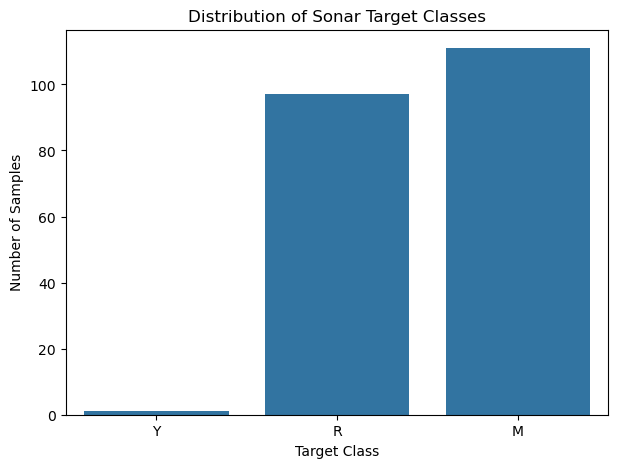

In [9]:
# Count each target class
print(df["Target"].value_counts())

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Target")

plt.title("Distribution of Sonar Target Classes")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")

plt.show()

In [10]:
print(df.head())
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset shape:", df.shape)

       V1      V2      V3      V4      V5      V6      V7      V8      V9  \
0     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1  0.0200  0.0371  0.0428  0.0207  0.0954  0.0986  0.1539  0.1601  0.3109   
2  0.0453  0.0523  0.0843  0.0689  0.1183  0.2583  0.2156  0.3481  0.3337   
3  0.0262  0.0582  0.1099  0.1083  0.0974  0.2280  0.2431  0.3771  0.5598   
4  0.0100  0.0171  0.0623  0.0205  0.0205  0.0368  0.1098  0.1276  0.0598   

      V10  ...     V52     V53     V54     V55     V56     V57     V58  \
0     NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1  0.2111  ...  0.0027  0.0065  0.0159  0.0072  0.0167  0.0180  0.0084   
2  0.2872  ...  0.0084  0.0089  0.0048  0.0094  0.0191  0.0140  0.0049   
3  0.6194  ...  0.0232  0.0166  0.0095  0.0180  0.0244  0.0316  0.0164   
4  0.1264  ...  0.0121  0.0036  0.0150  0.0085  0.0073  0.0050  0.0044   

      V59     V60  Target  
0     NaN     NaN       Y  
1  0.0090  0.0032       R  
2  0.005

In [11]:
print("Missing values:")
print(df.isnull().sum().sum())

print("Target classes:")
print(df["Target"].value_counts())

Missing values:
60
Target classes:
Target
M    111
R     97
Y      1
Name: count, dtype: int64


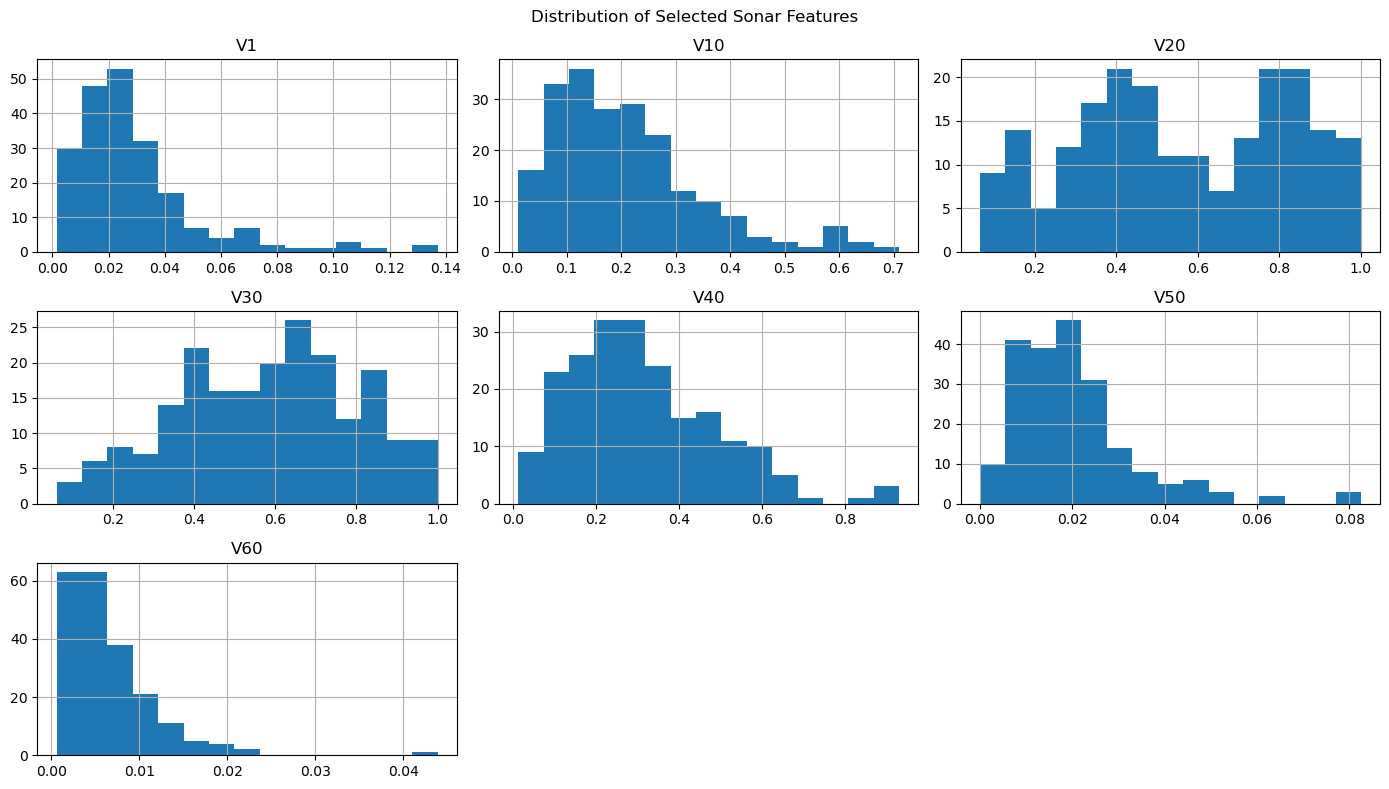

In [12]:
import matplotlib.pyplot as plt

selected_features = [
    "V1", "V10", "V20", "V30",
    "V40", "V50", "V60"
]

df[selected_features].hist(
    figsize=(14, 8),
    bins=15
)

plt.suptitle("Distribution of Selected Sonar Features")
plt.tight_layout()
plt.show()

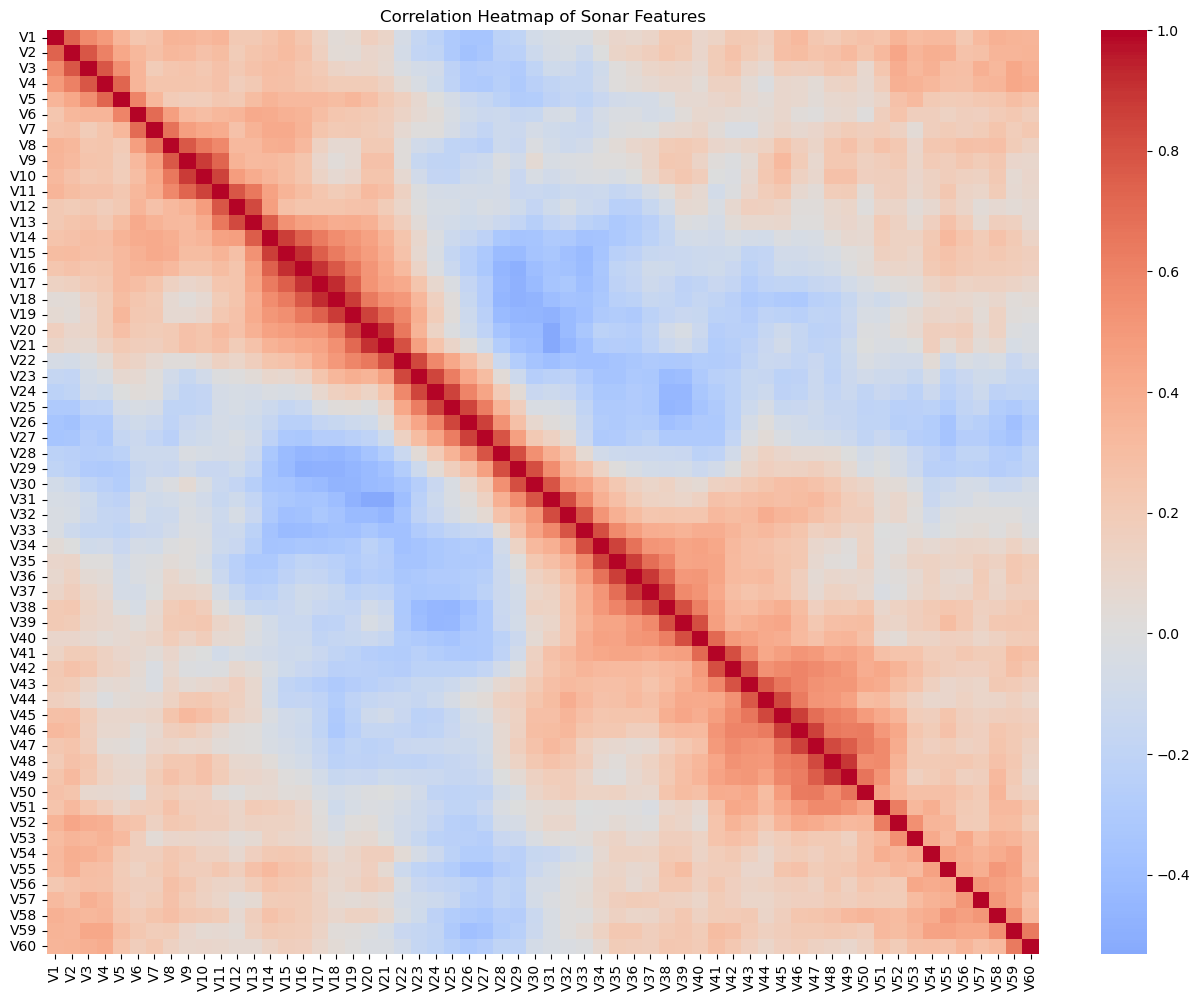

In [13]:
# Calculate correlation between numerical features
correlation = df.drop(columns="Target").corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Sonar Features")
plt.show()

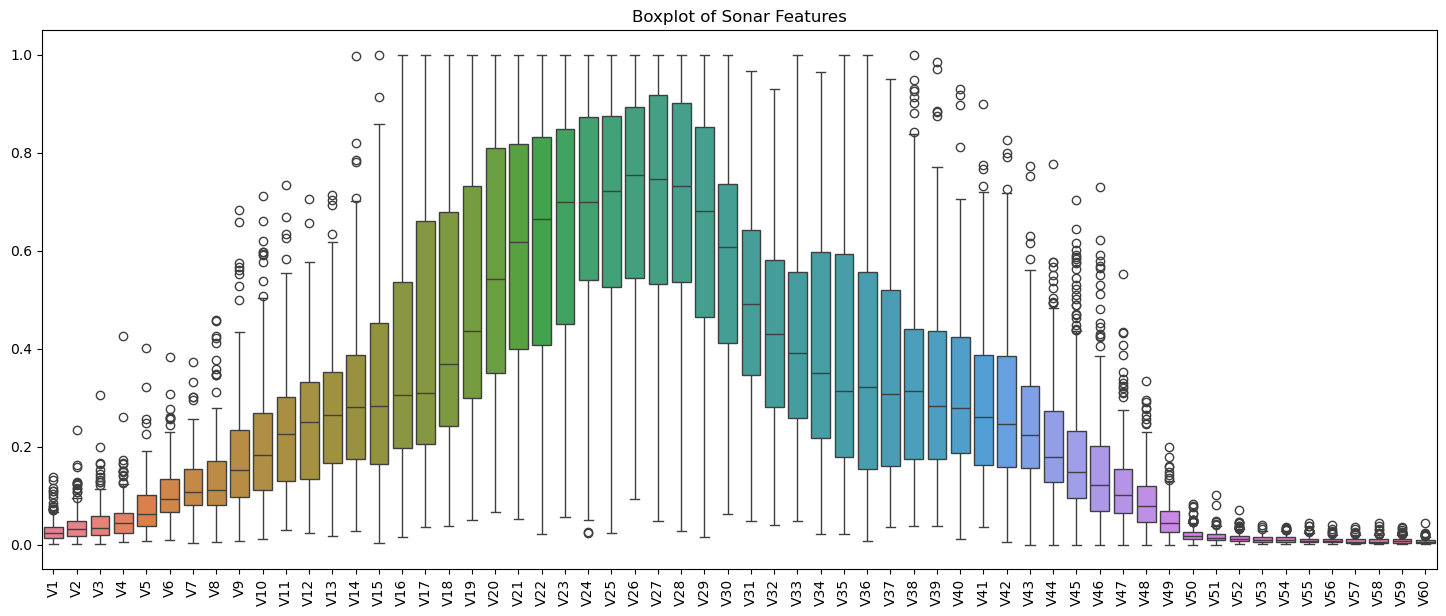

In [14]:
plt.figure(figsize=(18, 7))

sns.boxplot(data=df.drop(columns="Target"))

plt.title("Boxplot of Sonar Features")
plt.xticks(rotation=90)
plt.show()

5. Data preprocessing

5.1 Separate input features and target

In [15]:
# Input features
X = df.drop(columns="Target")

# Target variable
y = df["Target"]

# Encode categorical labels
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Encoded classes:", label_encoder.classes_)

Encoded classes: ['M' 'R' 'Y']


In [16]:
# Check for missing values
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", pd.isnull(y).sum())

# Replace missing numerical values with column median
X = X.fillna(X.median())

Missing values in X: 60
Missing values in y: 0


In [19]:
print("Target distribution:")
print(df["Target"].value_counts(dropna=False))

print("\nUnique target values:")
print(df["Target"].unique())

print("\nDataset shape:")
print(df.shape)

Target distribution:
Target
M    111
R     97
Y      1
Name: count, dtype: int64

Unique target values:
['Y' 'R' 'M']

Dataset shape:
(209, 61)


In [22]:
print("Target distribution:")
print(df["Target"].value_counts(dropna=False))

print("\nUnique target values:")
print(df["Target"].unique())

print("\nDataset shape:")
print(df.shape)

Target distribution:
Target
M    111
R     97
Y      1
Name: count, dtype: int64

Unique target values:
['Y' 'R' 'M']

Dataset shape:
(209, 61)


In [23]:
# Remove unnecessary spaces from target labels
df["Target"] = df["Target"].astype(str).str.strip().str.upper()

# Keep only valid target classes
df = df[df["Target"].isin(["M", "R"])].copy()

# Separate input features
X = df.drop(columns=["Target"])

# Convert features to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Handle missing values
X = X.fillna(X.median())

# Encode target labels
y = df["Target"].map({
    "M": 0,
    "R": 1
})

# Check class distribution
print("Target distribution:")
print(y.value_counts())

print("\nUnique classes:", y.nunique())
print("X shape:", X.shape)
print("y shape:", y.shape)

Target distribution:
Target
0    111
1     97
Name: count, dtype: int64

Unique classes: 2
X shape: (208, 60)
y shape: (208,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 166
Testing samples: 42

Training class distribution:
Target
0    89
1    77
Name: count, dtype: int64

Testing class distribution:
Target
0    22
1    20
Name: count, dtype: int64


6. Build the basic ANN model

6.1 Define the ANN architecture

In [25]:
# Create ANN model
model = Sequential([

    # Input layer
    Input(shape=(60,)),

    # Hidden layer
    Dense(16, activation="relu"),

    # Output layer
    Dense(1, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

6.2 Train the ANN

In [28]:
#6.2 Train the ANN Early stopping prevents unnecessary training
from sklearn.preprocessing import StandardScaler
# Create StandardScaler object
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

# Display shapes
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.20,
    callbacks=[early_stopping],
    verbose=1
)

Scaled training data: (166, 60)
Scaled testing data: (42, 60)
Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5833 - loss: 0.7703 - val_accuracy: 0.5000 - val_loss: 0.8525
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6212 - loss: 0.6807 - val_accuracy: 0.5882 - val_loss: 0.7507
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6667 - loss: 0.6165 - val_accuracy: 0.6471 - val_loss: 0.6777
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7348 - loss: 0.5659 - val_accuracy: 0.6765 - val_loss: 0.6249
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7576 - loss: 0.5250 - val_accuracy: 0.7059 - val_loss: 0.5850
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7576 - loss: 0.4920 - val_accuracy: 0.7353 - val_loss: 0.5525
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8106 - loss: 0.4636 - val_accuracy: 0.7647 - val_loss: 0.5249
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy:

6.3 Plot training performance

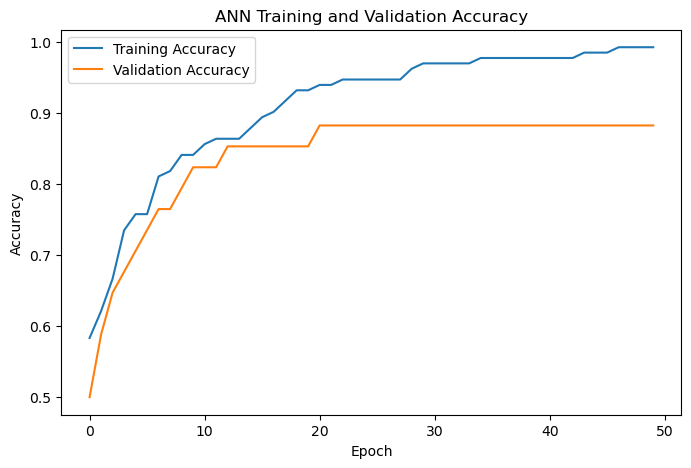

In [29]:
# Plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

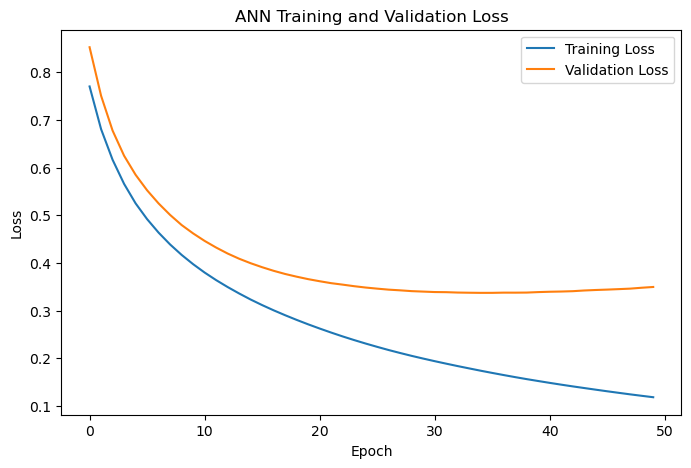

In [30]:
# Plot loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

7. Evaluate the default ANN model

7.1 Generate predictions

In [31]:
# Predict probabilities
y_pred_probability = model.predict(X_test_scaled)

# Convert probabilities into binary predictions
y_pred = (y_pred_probability >= 0.5).astype(int).flatten()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


7.2 Calculate evaluation metrics

In [32]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Precision
precision = precision_score(y_test, y_pred, zero_division=0)

# Recall
recall = recall_score(y_test, y_pred, zero_division=0)

# F1-score
f1 = f1_score(y_test, y_pred, zero_division=0)

# ROC-AUC
roc_auc = roc_auc_score(y_test, y_pred_probability)

print("DEFAULT ANN MODEL PERFORMANCE")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

DEFAULT ANN MODEL PERFORMANCE
--------------------------------
Accuracy : 0.8333
Precision: 0.9333
Recall   : 0.7
F1-score : 0.8
ROC-AUC  : 0.8841


7.3 Classification report

In [33]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Mine", "Rock"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

        Mine       0.78      0.95      0.86        22
        Rock       0.93      0.70      0.80        20

    accuracy                           0.83        42
   macro avg       0.86      0.83      0.83        42
weighted avg       0.85      0.83      0.83        42



7.4 Confusion matrix

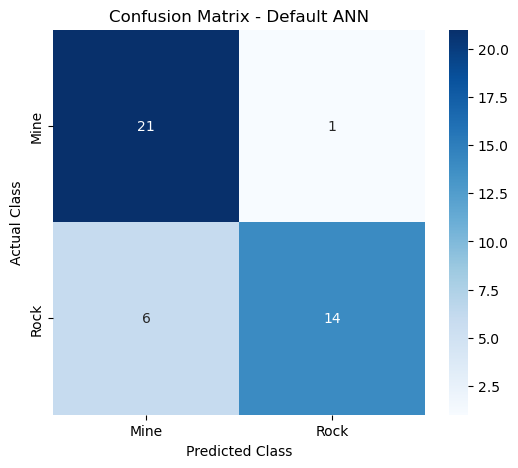

In [34]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Mine", "Rock"],
    yticklabels=["Mine", "Rock"]
)

plt.title("Confusion Matrix - Default ANN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

7.5 ROC curve

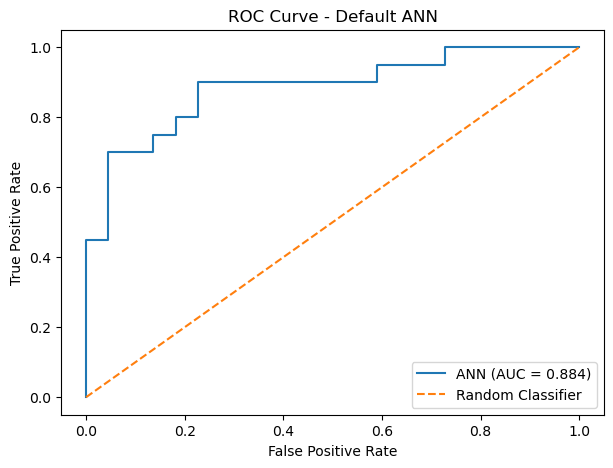

In [35]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ANN (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Default ANN")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.show()

8. Hyperparameter tuning

8.1 Define a model-building function

In [36]:
def build_ann(
    neurons=16,
    hidden_layers=1,
    activation="relu",
    learning_rate=0.001
):
    """
    Create an ANN model with configurable hyperparameters.
    """

    model = Sequential()

    # Input layer
    model.add(Input(shape=(60,)))

    # First hidden layer
    model.add(Dense(neurons, activation=activation))

    # Optional second hidden layer
    if hidden_layers == 2:
        model.add(Dense(neurons, activation=activation))

    # Output layer
    model.add(Dense(1, activation="sigmoid"))

    # Compile model
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

8.2 Define hyperparameter combinations

In [37]:
# Hyperparameter configurations
param_grid = [
    {
        "neurons": 16,
        "hidden_layers": 1,
        "activation": "relu",
        "learning_rate": 0.001,
        "batch_size": 16
    },
    {
        "neurons": 32,
        "hidden_layers": 1,
        "activation": "relu",
        "learning_rate": 0.001,
        "batch_size": 16
    },
    {
        "neurons": 32,
        "hidden_layers": 2,
        "activation": "relu",
        "learning_rate": 0.001,
        "batch_size": 16
    },
    {
        "neurons": 32,
        "hidden_layers": 1,
        "activation": "tanh",
        "learning_rate": 0.0005,
        "batch_size": 32
    },
    {
        "neurons": 64,
        "hidden_layers": 2,
        "activation": "relu",
        "learning_rate": 0.0005,
        "batch_size": 32
    }
]

8.3 Perform 3-fold cross-validation

In [41]:
# Convert Pandas Series into NumPy arrays
y_train = np.asarray(y_train)
y_test = np.asarray(y_test)

print("y_train type:", type(y_train))
print("y_test type:", type(y_test))

y_train type: <class 'numpy.ndarray'>
y_test type: <class 'numpy.ndarray'>


In [40]:
# Stratified cross-validation
skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results = []

for params in param_grid:

    fold_accuracies = []

    print("\nTesting configuration:", params)

    for train_idx, val_idx in skf.split(
        X_train_scaled,
        y_train
    ):

        # Split training and validation data
        X_fold_train = X_train_scaled[train_idx]
        X_fold_val = X_train_scaled[val_idx]

        # Correct positional indexing
        y_fold_train = y_train[train_idx]
        y_fold_val = y_train[val_idx]

        # Clear previous TensorFlow session
        tf.keras.backend.clear_session()

        # Build ANN
        fold_model = build_ann(
            neurons=params["neurons"],
            hidden_layers=params["hidden_layers"],
            activation=params["activation"],
            learning_rate=params["learning_rate"]
        )

        # Train ANN
        fold_model.fit(
            X_fold_train,
            y_fold_train,
            epochs=100,
            batch_size=params["batch_size"],
            validation_data=(
                X_fold_val,
                y_fold_val
            ),
            callbacks=[
                EarlyStopping(
                    monitor="val_loss",
                    patience=10,
                    restore_best_weights=True
                )
            ],
            verbose=0
        )

        # Evaluate model
        _, fold_accuracy = fold_model.evaluate(
            X_fold_val,
            y_fold_val,
            verbose=0
        )

        fold_accuracies.append(fold_accuracy)

    # Calculate average accuracy
    mean_accuracy = np.mean(fold_accuracies)

    results.append({
        **params,
        "CV Accuracy": mean_accuracy
    })

    print(
        "Mean CV Accuracy:",
        round(mean_accuracy, 4)
    )

print("\nHyperparameter tuning completed!")


Testing configuration: {'neurons': 16, 'hidden_layers': 1, 'activation': 'relu', 'learning_rate': 0.001, 'batch_size': 16}

Mean CV Accuracy: 0.801

Testing configuration: {'neurons': 32, 'hidden_layers': 1, 'activation': 'relu', 'learning_rate': 0.001, 'batch_size': 16}
Mean CV Accuracy: 0.7771

Testing configuration: {'neurons': 32, 'hidden_layers': 2, 'activation': 'relu', 'learning_rate': 0.001, 'batch_size': 16}
Mean CV Accuracy: 0.8195

Testing configuration: {'neurons': 32, 'hidden_layers': 1, 'activation': 'tanh', 'learning_rate': 0.0005, 'batch_size': 32}
Mean CV Accuracy: 0.7289

Testing configuration: {'neurons': 64, 'hidden_layers': 2, 'activation': 'relu', 'learning_rate': 0.0005, 'batch_size': 32}
Mean CV Accuracy: 0.7769

Hyperparameter tuning completed!


In [43]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV Accuracy",
    ascending=False
).reset_index(drop=True)

display(results_df)

,neurons,hidden_layers,activation,learning_rate,batch_size,CV Accuracy
0,32,2,relu,0.0010,16,0.819481
1,16,1,relu,0.0010,16,0.800974
2,32,1,relu,0.0010,16,0.777056
3,64,2,relu,0.0005,32,0.776948
4,32,1,tanh,0.0005,32,0.728896


8.4 Compare hyperparameter configurations

In [42]:
# Convert results into DataFrame
results_df = pd.DataFrame(results)

# Sort configurations by CV accuracy
results_df = results_df.sort_values(
    by="CV Accuracy",
    ascending=False
)

display(results_df)

,neurons,hidden_layers,activation,learning_rate,batch_size,CV Accuracy
2,32,2,relu,0.0010,16,0.819481
0,16,1,relu,0.0010,16,0.800974
1,32,1,relu,0.0010,16,0.777056
4,64,2,relu,0.0005,32,0.776948
3,32,1,tanh,0.0005,32,0.728896


8.5 Visualize tuning results

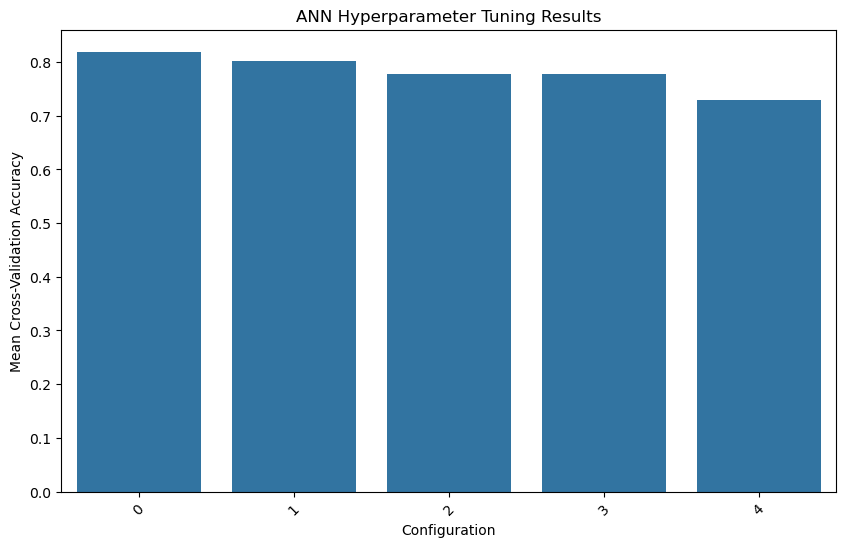

In [44]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x=results_df.index,
    y="CV Accuracy"
)

plt.title("ANN Hyperparameter Tuning Results")
plt.xlabel("Configuration")
plt.ylabel("Mean Cross-Validation Accuracy")

plt.xticks(rotation=45)
plt.show()

8.6 Select the best configuration

In [45]:
# Select the configuration with highest CV accuracy
best_params = results_df.iloc[0].to_dict()

print("Best Hyperparameters:")
print(best_params)

Best Hyperparameters:
{'neurons': 32, 'hidden_layers': 2, 'activation': 'relu', 'learning_rate': 0.001, 'batch_size': 16, 'CV Accuracy': 0.8194805185000101}


9. Train the tuned ANN model

In [46]:
# Clear previous model
tf.keras.backend.clear_session()

# Build tuned ANN
tuned_model = build_ann(
    neurons=int(best_params["neurons"]),
    hidden_layers=int(best_params["hidden_layers"]),
    activation=best_params["activation"],
    learning_rate=float(best_params["learning_rate"])
)

# Train tuned model
tuned_history = tuned_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=int(best_params["batch_size"]),
    validation_split=0.20,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6136 - loss: 0.6928 - val_accuracy: 0.7353 - val_loss: 0.5697
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7348 - loss: 0.5831 - val_accuracy: 0.7941 - val_loss: 0.5407
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7803 - loss: 0.5232 - val_accuracy: 0.7941 - val_loss: 0.5056
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8106 - loss: 0.4751 - val_accuracy: 0.8235 - val_loss: 0.4703
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8182 - loss: 0.4328 - val_accuracy: 0.8529 - val_loss: 0.4375
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8409 - loss: 0.3956 - val_accuracy: 0.8529 - val_loss: 0.4118
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8712 - loss: 0.3631 - val_accuracy: 0.8529 - val_loss: 0.3922
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8939 - loss: 0.3345 - val_accuracy: 0.8529 - val_loss: 0.37

9.1 Evaluate the tuned model

In [47]:
# Generate predictions
tuned_probability = tuned_model.predict(X_test_scaled)

tuned_pred = (
    tuned_probability >= 0.5
).astype(int).flatten()

# Calculate metrics
tuned_accuracy = accuracy_score(y_test, tuned_pred)

tuned_precision = precision_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_auc = roc_auc_score(
    y_test,
    tuned_probability
)

print("TUNED ANN MODEL PERFORMANCE")
print("--------------------------------")
print("Accuracy :", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall   :", round(tuned_recall, 4))
print("F1-score :", round(tuned_f1, 4))
print("ROC-AUC  :", round(tuned_auc, 4))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
TUNED ANN MODEL PERFORMANCE
--------------------------------
Accuracy : 0.8095
Precision: 0.8333
Recall   : 0.75
F1-score : 0.7895
ROC-AUC  : 0.8909


10. Compare default and tuned ANN models

In [48]:
# Create comparison table
comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Default ANN": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],

    "Tuned ANN": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_auc
    ]
})

display(comparison_df.round(4))

,Metric,Default ANN,Tuned ANN
0,Accuracy,0.8333,0.8095
1,Precision,0.9333,0.8333
2,Recall,0.7000,0.7500
3,F1-score,0.8000,0.7895
4,ROC-AUC,0.8841,0.8909


10.1 Visualize model comparison

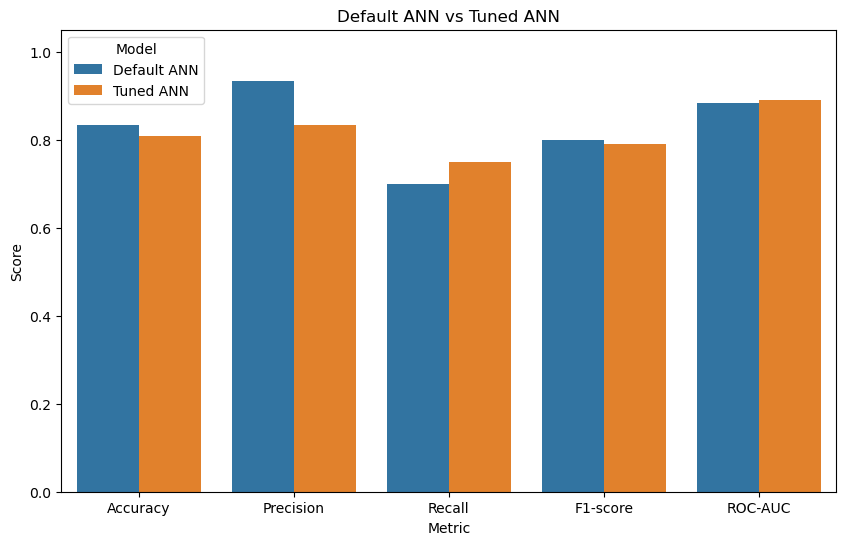

In [49]:
comparison_plot = comparison_df.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Default ANN vs Tuned ANN")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.show()

10.2 Calculate improvement

In [50]:
accuracy_improvement = (
    tuned_accuracy - accuracy
) * 100

print(
    "Accuracy improvement:",
    round(accuracy_improvement, 2),
    "percentage points"
)

Accuracy improvement: -2.38 percentage points
